# 프롬프트 캐시 계측

**이 노트북에서 할 일**

1. 긴 정책 글 뒤에 문의 글을 붙인 요청을 두 번 보내고, 사용량에서 캐시 입력 토큰 수를 읽습니다.
2. 문의 글을 정책 글 앞에 두는 값 하나만 바꿔 같은 두 요청을 다시 보내고, 두 실행을 견줍니다.
3. 도구 파일의 함수 `estimate_cost`로 네 요청의 예상 비용을 어림합니다.

**준비물** — 이 노트북은 실제 모델에 요청을 네 번 보냅니다.
실행 1에서 두 번, 실행 2에서 두 번입니다.
프로젝트 폴더의 `.env` 파일에 `OPENAI_API_KEY`가 있어야 합니다.
키가 없으면 키를 확인하는 셀에서 멈추고, 모델 요청은 나가지 않습니다.

요금표(2026-09-29 확인)로 어림한 비용은 네 번을 합쳐 0.01달러보다 적습니다.
청구 금액이 아니라, 교재를 만들 때 본 사용량으로 어림한 값입니다.
실행마다 답 글과 토큰 수가 달라질 수 있습니다.
걸린 시간은 재지 않았습니다.

교재를 만들 때 같은 요청 넷을 노트북 밖에서 다섯 번 더 보내 보았고, 이를 흔들림 확인이라고 부릅니다.
새 커널 두 번은 프로젝트 맨 위와 `notebooks/` 폴더에서 새 커널을 하나씩 열어, 이 노트북을 두 번 실행한 것입니다.

실습 폴더의 도구 파일 `cost_tools.py`에서 함수 하나를 가져옵니다.
이 노트북은 파일을 쓰지 않습니다.

**기준 버전** — 첫 셀에서 패키지 셋을 설치합니다.
버전은 langchain 1.4.0, langchain-openai 1.6.0, python-dotenv 1.2.3입니다.
셋 모두 실습 폴더 잠금과 같은 버전입니다.
교재 출력은 Linux의 Python 3.12.13으로 만들었습니다.
다른 버전과 Windows·macOS에서는 실행하지 않았습니다.

**강의와 실습 범위** — 강의 시간에는 2절의 요청 글 모양을 보고 가설을 함께 세웁니다.
모델에 요청을 보내는 3·4절과 표를 만드는 5·6절은 실습 시간에 실행합니다.

실습 폴더 `labs/part7/ch34-cost-rate-limits`에서 `uv sync --locked`를 실행합니다.
그다음 `notebooks/` 폴더의 이 노트북을 열고, 실습 폴더의 `.venv` 커널을 고릅니다.
첫 셀부터 순서대로 실행합니다.

## 오늘 볼 그림

![위에서 아래로 읽는 흐름도입니다. 맨 위 파란 상자 make_request 번호는 늘 맨 앞 앞 글과 뒤 글의 차례만 바꿈에서 칸 둘로 갈라집니다. 왼쪽 칸 실행 1 문의 글을 뒤에는 초록 상자 첫 요청 번호 정책 문의 1과 초록 상자 둘째 요청 번호 정책 문의 2 아래에 회색 상자 첫 글자부터 같은 부분 번호와 정책 글 전체가 있습니다. 오른쪽 칸 실행 2 문의 글을 앞에는 초록 상자 첫 요청 번호 문의 1 정책과 초록 상자 둘째 요청 번호 문의 2 정책 아래에 회색 상자 첫 글자부터 같은 부분 번호뿐이 있는 그림](attachment:01-1-요청-글의-두-차례.png)

위에서 아래로 읽습니다.
파란 상자는 우리가 정의한 함수이고, 초록 상자는 그 함수로 만든 요청 글입니다.
왼쪽 칸이 실행 1, 오른쪽 칸이 실행 2입니다.
칸마다 아래 회색 상자는 두 요청 글이 첫 글자부터 같은 부분을 코드의 차례로 셈한 것입니다.
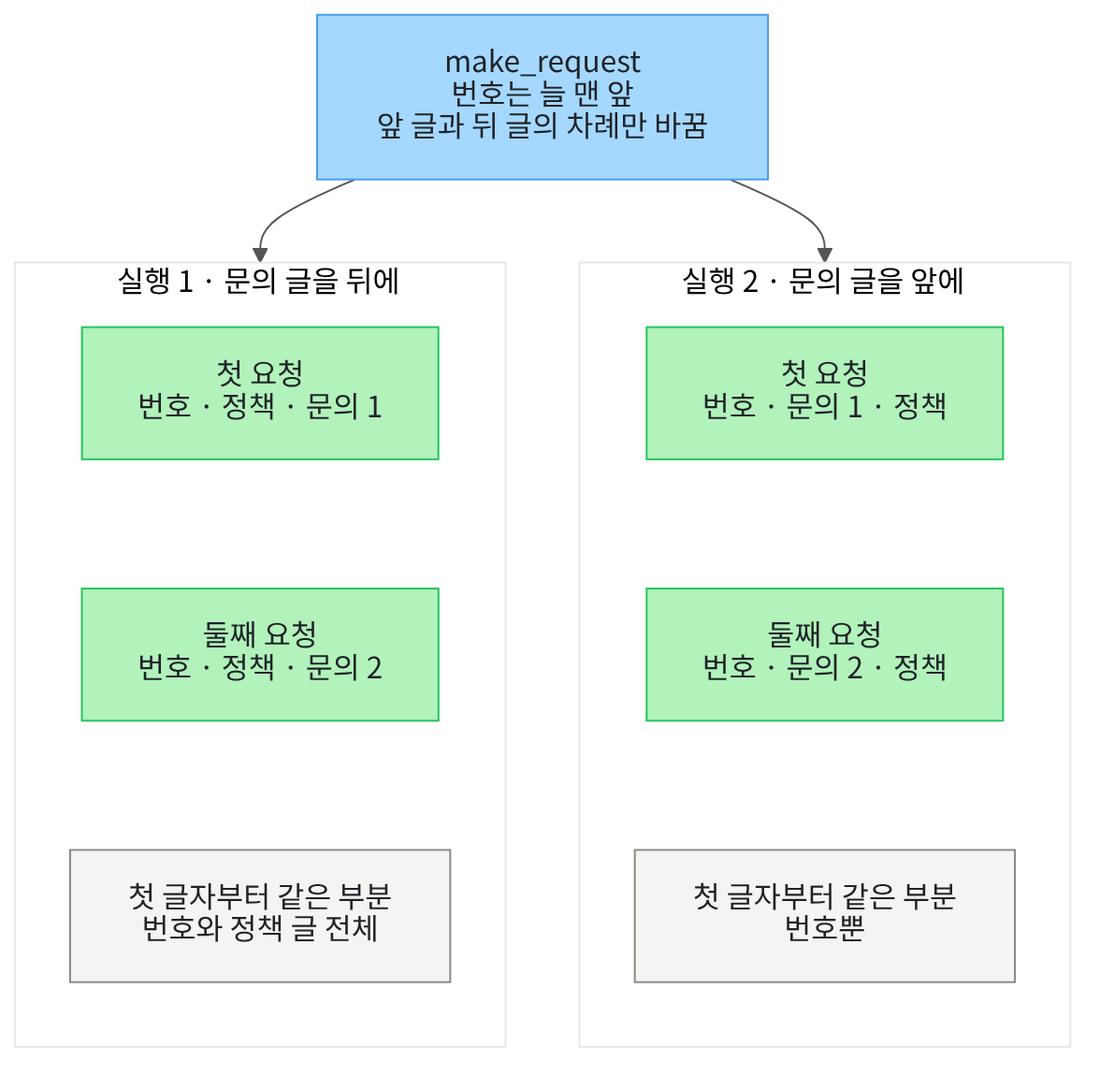

## 1. 준비

제목의 프롬프트 캐시 계측은, 제공자가 앞 요청의 앞부분을 다시 쓴 양을 사용량에서 세어 보는 일입니다.
Ch 6 06절에서는 이렇게 다시 쓴 입력 토큰을 캐시 입력이라고 불렀습니다.
이 절도 그 말을 그대로 씁니다.
이 챕터에서 토큰은 Ch 5에서 배운, 모델이 글을 나눠 세는 단위만 뜻합니다.
Ch 28·30에서 쓴 접근 토큰과는 다른 말입니다.

첫 셀은 패키지 셋을 설치하고 설치된 버전을 출력합니다.
설치에는 몇십 초가 걸릴 수 있습니다.

In [1]:
# 이 절에서 쓰는 패키지를 설치하고 버전을 확인합니다
%pip install -q "langchain==1.4.0" "langchain-openai==1.6.0" "python-dotenv==1.2.3"
from importlib.metadata import version

print("langchain:", version("langchain"))
print("langchain-openai:", version("langchain-openai"))
print("python-dotenv:", version("python-dotenv"))

Note: you may need to restart the kernel to use updated packages.
langchain: 1.4.0
langchain-openai: 1.6.0
python-dotenv: 1.2.3


**결과 읽기** — 출력 줄 `langchain: 1.4.0`과 `langchain-openai: 1.6.0`이 보입니다.
패키지 python-dotenv는 `.env` 파일에서 키를 읽을 때 씁니다.
세 패키지 모두 Ch 6 06절과 같은 버전입니다.

다음 셀은 이 절에서 쓸 이름을 가져옵니다.
Ch 6 06절에서 배운 함수 `estimate_cost`는 도구 파일 `cost_tools.py`에서 가져옵니다.

In [2]:
# 이 절에서 쓸 이름을 가져옵니다(uuid는 Python에 들어 있는 모듈입니다)
import uuid
from langchain.chat_models import init_chat_model
# Ch 6 06절에서 배운 함수는 도구 파일에서 가져옵니다
from cost_tools import estimate_cost

print("가져온 이름:", "uuid, init_chat_model")
print("도구 파일에서 가져온 함수:", estimate_cost.__name__)

가져온 이름: uuid, init_chat_model
도구 파일에서 가져온 함수: estimate_cost


**결과 읽기** — 출력 줄 `도구 파일에서 가져온 함수: estimate_cost`가 보입니다.
이 함수는 Ch 6 06절 셀의 함수와 def 줄부터 끝 줄까지 글자가 같고, 이 절에서 도구 파일에 처음 옮겼습니다.
모듈 uuid는 Python에 들어 있는 모듈로, 2절에서 실험 번호를 만들 때 씁니다.

앞에서 배운 함수는 `cost_tools.py`에 모아 두었습니다.
파일을 열면 코드를 볼 수 있습니다.
노트북과 같은 폴더(`notebooks/`)에 있는 파일입니다.
커널이 `notebooks/` 폴더에서 시작해야 이 파일을 가져올 수 있습니다.
교재 출력을 만든 실행 도구는 이 폴더를 따로 알려 주어, 다른 자리에서 시작해도 가져오기가 되었습니다.

다음 셀은 `.env` 파일에서 API 키를 읽고, 키가 있는지만 출력합니다.

In [3]:
# .env 파일에서 OpenAI API 키를 읽습니다(키 값은 출력하지 않습니다)
import os
from dotenv import find_dotenv, load_dotenv

env_path = find_dotenv(usecwd=True)
load_dotenv(env_path)
has_key = os.getenv("OPENAI_API_KEY") is not None
print("OPENAI_API_KEY 설정 여부:", has_key)
assert has_key, "프로젝트 폴더의 .env 파일에 OPENAI_API_KEY를 적어 주세요."

OPENAI_API_KEY 설정 여부: True


**결과 읽기** — 출력 줄 `OPENAI_API_KEY 설정 여부: True`가 보입니다.
키 값은 출력하지 않고, 있는지만 봅니다.
키가 없으면 이 셀의 `assert`가 멈추고, 뒤 셀의 모델 요청도 나가지 않습니다.

다음 셀은 과정 표준 설정으로 모델 객체를 만듭니다.
객체를 만들 때는 모델 요청이 나가지 않습니다.

In [4]:
# 실습에 쓸 모델을 준비합니다
model = init_chat_model(
    "openai:gpt-5.4-mini",
    temperature=0,
    reasoning_effort="none",
)
print("모델 이름:", model.model_name)
print("temperature:", model.temperature)

모델 이름: gpt-5.4-mini
temperature: 0.0


**결과 읽기** — 모델 이름 `gpt-5.4-mini`, temperature `0.0`이 보이면 준비가 끝났습니다.
이 노트북의 출력은 2026-09-29에 이 모델로 실행한 결과입니다.
온도 값을 0으로 두어도 모델의 답이 매번 같다고 할 수는 없습니다.
인자 `reasoning_effort="none"`은 모델이 답하기 전에 따로 생각하는 단계를 쓰지 않게 합니다.

## 2. 요청마다 같은 글과 바뀌는 글

상담 서비스는 요청마다 같은 정책 글을 모델에 보내고, 그 끝에 손님의 문의 글을 붙이곤 합니다.
여러 요청이 첫 글자부터 똑같이 보내는 부분을 이 절에서는 공통 앞부분이라고 부릅니다.
매일 같은 인사말과 규정 안내로 시작하는 상담 메일의 머리와 같습니다.
이 절 코드에서는 실험 번호와 정책 글이 실행 1의 두 요청에 공통인 앞부분입니다.

다음 셀은 규칙 문장 하나를 100번 이어 붙여 긴 정책 글을 만듭니다.
Ch 6 06절의 긴 시스템 메시지처럼, 캐시 입력이 생길 만큼 길게 만들려고 같은 문장을 되풀이합니다.

In [5]:
# 규칙 문장 하나를 100번 이어 붙여, 요청마다 똑같이 보낼 긴 정책 글을 만듭니다
rule_sentence = "고객 문의에 답할 때는 확인한 주문 정보만 근거로 삼고, 확인하지 못한 내용은 확인하지 못했다고 적습니다. "
repeat_count = 100
policy_text = ""
for number in range(repeat_count):
    policy_text = policy_text + rule_sentence
print("규칙 문장의 글자 수:", len(rule_sentence))
print("정책 글의 글자 수:", len(policy_text))

규칙 문장의 글자 수: 60
정책 글의 글자 수: 6000


**결과 읽기** — 출력 줄 `정책 글의 글자 수: 6000`이 보입니다.
규칙 문장 하나가 끝 공백까지 `60`글자라, 100번 이으면 6000글자입니다.
이 길이는 Ch 6 06절에서 캐시 입력이 생긴 긴 시스템 메시지(규칙 문장 80번)보다 조금 깁니다.

다음 셀은 요청마다 바뀌는 문의 글 둘을 목록에 담습니다.
요청마다 달라지는 부분을 이 절에서는 바뀌는 글이라고 부릅니다.
가게 게시판에서 매일 바꿔 붙이는 오늘의 안내 한 줄과 같습니다.

In [6]:
# 요청마다 바뀌는 문의 글 둘을 목록에 담습니다(두 글은 첫 글자부터 다릅니다)
inquiries = [
    "주문한 책이 일주일째 오지 않습니다. 이 문의의 종류를 배송, 환불, 결제 가운데 한 낱말로 답하세요.",
    "받은 책이 찢어져 있어 돈을 되찾고 싶습니다. 이 문의의 종류를 배송, 환불, 결제 가운데 한 낱말로 답하세요.",
]
print("문의 글 1:", inquiries[0])
print("문의 글 2:", inquiries[1])
print("두 문의 글의 첫 글자:", inquiries[0][0], inquiries[1][0])

문의 글 1: 주문한 책이 일주일째 오지 않습니다. 이 문의의 종류를 배송, 환불, 결제 가운데 한 낱말로 답하세요.
문의 글 2: 받은 책이 찢어져 있어 돈을 되찾고 싶습니다. 이 문의의 종류를 배송, 환불, 결제 가운데 한 낱말로 답하세요.
두 문의 글의 첫 글자: 주 받


**결과 읽기** — 출력 줄 `두 문의 글의 첫 글자: 주 받`이 보입니다.
두 문의 글은 첫 글자부터 달라, 문의 글끼리는 첫 글자부터 같은 부분이 없습니다.
두 문의 모두 종류를 배송, 환불, 결제 가운데 한 낱말로 답하게 해서, 출력 토큰이 적게 나오게 했습니다.

다음 셀은 이 실행에서만 쓸 실험 번호를 만듭니다.
실험 번호를 요청 글 맨 앞에 두면, 앞서 실행한 노트북의 요청과 첫 부분부터 달라집니다.
그래서 이 실행의 첫 요청은 앞 실행이 남긴 앞부분을 다시 쓸 수 없습니다.
Ch 6 06절은 같은 목적으로 지금 시각을 맨 앞에 두었습니다.

In [7]:
# 이 실행에서만 쓸 실험 번호를 만듭니다(번호는 실행마다 달라서 글자 수만 출력합니다)
# uuid.uuid4()는 겹치지 않는 무작위 값을 만들고, 속성 hex는 그 값을 32글자 글로 내놓습니다
experiment_mark = "실험 번호 " + uuid.uuid4().hex
print("실험 번호의 글자 수:", len(experiment_mark))

실험 번호의 글자 수: 38


**결과 읽기** — 출력 줄 `실험 번호의 글자 수: 38`이 보입니다.
「실험 번호 」 여섯 글자 뒤에 무작위 32글자가 붙었습니다.
번호 자체는 실행마다 달라서 출력하지 않습니다.

다음 셀은 실험 번호·앞 글·뒤 글을 이어 요청 글 하나를 만드는 함수를 정의합니다.
두 글 가운데 무엇을 앞에 둘지는 인자의 차례로 정합니다.

In [8]:
# 실험 번호·앞 글·뒤 글을 줄바꿈으로 이어, 모델에 보낼 요청 글 하나를 만듭니다
def make_request(mark, first_text, second_text):
    # 실험 번호는 언제나 맨 앞에 두고, 정책 글과 문의 글의 차례만 인자로 정합니다
    request_text = mark + "\n" + first_text + "\n" + second_text
    return request_text

**결과 읽기** — 정의 셀이라 출력이 없습니다.
글 사이에 넣은 `"\n"`은 줄바꿈 한 글자입니다.
실험 번호는 늘 맨 앞에 두고, 정책 글과 문의 글의 차례만 바꿀 수 있게 했습니다.

다음 셀은 문의 글 1로 두 가지 차례의 요청 글을 만들고, 정책 글이 시작하는 자리를 견줍니다.
메서드 `find`는 글 안에서 찾는 글이 처음 시작하는 자리를 0부터 센 번호로 내놓습니다.

In [9]:
# 문의 글 1로 두 가지 차례의 요청 글을 만들어, 정책 글이 시작하는 자리를 견줍니다
after_text = make_request(experiment_mark, policy_text, inquiries[0])
before_text = make_request(experiment_mark, inquiries[0], policy_text)
print("두 요청 글의 글자 수:", len(after_text), len(before_text))
# 메서드 find는 찾는 글이 처음 시작하는 자리를 0부터 센 번호로 내놓습니다
print("정책 글이 시작하는 자리(문의 글을 뒤에 둘 때):", after_text.find(policy_text))
print("정책 글이 시작하는 자리(문의 글을 앞에 둘 때):", before_text.find(policy_text))

두 요청 글의 글자 수: 6097 6097
정책 글이 시작하는 자리(문의 글을 뒤에 둘 때): 39
정책 글이 시작하는 자리(문의 글을 앞에 둘 때): 97


**결과 읽기** — 출력 줄 `두 요청 글의 글자 수: 6097 6097`이 보입니다.
두 글은 같은 글을 차례만 바꿔 이었으므로 길이가 같습니다.
정책 글은 문의 글을 뒤에 둘 때 `39`번 자리에서, 앞에 둘 때 `97`번 자리에서 시작합니다.
실험 번호 38글자와 줄바꿈 한 글자 뒤가 39번 자리입니다.
앞에 둘 때는 그 사이에 문의 글 57글자와 줄바꿈 한 글자가 더 끼었습니다.

**가설** — 캐시 입력은 공통 앞부분을 다시 쓴 입력 토큰입니다.
문의 글을 정책 글 뒤에 두면, 두 요청은 실험 번호와 정책 글까지 첫 글자부터 같습니다.
그러면 둘째 요청에서 캐시 입력이 생길 수 있습니다.
문의 글을 정책 글 앞에 두면, 두 요청은 실험 번호 바로 뒤부터 달라집니다.
그러면 둘째 요청도 캐시 입력이 0일 것입니다.

## 3. 실행 1 — 문의 글을 정책 글 뒤에

다음 셀은 실행 1의 첫 요청으로, 문의 글 1을 정책 글 뒤에 둔 글을 보냅니다.
Ch 6 01절처럼 글 하나를 메서드 `invoke`에 넣으면, 사용자 메시지 하나로 보냅니다.
이 셀에서 모델 요청이 한 번 나갑니다.

In [10]:
# 실행 1의 첫 요청: 문의 글 1을 정책 글 뒤에 둔 글을 보냅니다(모델 요청 1번)
after_first = model.invoke(after_text)
after_first_usage = after_first.usage_metadata
print("답:", after_first.text)
print("입력 토큰 수:", after_first_usage["input_tokens"])
print("캐시 입력 토큰 수:", after_first_usage["input_token_details"]["cache_read"])

답: 배송
입력 토큰 수: 3166
캐시 입력 토큰 수: 0


**결과 읽기** — 출력 줄 `캐시 입력 토큰 수: 0`이 보입니다.
이 요청은 이 실행에서 처음 보낸 글이고, 맨 앞의 실험 번호가 앞 실행의 글과 다릅니다.
그래서 다시 쓸 앞부분이 없었습니다.
흔들림 확인 다섯 번에서도 첫 요청의 캐시 입력은 모두 0이었습니다.

교재 출력에서는 답이 `배송`, 입력 토큰 수가 `3166`이었습니다.
입력 토큰 수는 실험 번호가 토큰 몇 개로 나뉘는지에 따라 실행마다 조금 달라집니다.
답 글도 모델이 쓴 글이라 실행마다 달라질 수 있습니다.

다음 셀은 사용량의 안쪽 딕셔너리를 보고, 사용량 원본의 안쪽 칸도 봅니다.
사용량 원본은 응답 객체의 `response_metadata`에서 키 `token_usage`로 꺼냅니다.
라이브러리가 받은 사용량을 딕셔너리로 바꾼 것이라, 값이 없던 칸은 None으로 보입니다.

In [11]:
# 첫 요청의 사용량 안쪽 딕셔너리와, 사용량 원본(token_usage)의 안쪽 칸을 봅니다(요청 없음)
raw_usage = after_first.response_metadata["token_usage"]
print("input_token_details:", after_first_usage["input_token_details"])
print("키 cache_creation이 있는가:", "cache_creation" in after_first_usage["input_token_details"])
print("prompt_tokens_details:", raw_usage["prompt_tokens_details"])

input_token_details: {'audio': 0, 'cache_read': 0}
키 cache_creation이 있는가: False
prompt_tokens_details: {'audio_tokens': 0, 'cache_write_tokens': None, 'cached_tokens': 0, 'image_tokens': None, 'text_tokens': None}


**결과 읽기** — 출력 줄 `input_token_details: {'audio': 0, 'cache_read': 0}`이 보입니다.
키 `cache_read`가 캐시 입력 토큰 수이고, 다음 줄 `False`처럼 키 `cache_creation`은 없습니다.
사용량 원본의 안쪽 칸에는 `'cached_tokens': 0`과 `'cache_write_tokens': None`이 있습니다.
라이브러리 LangChain은 원본의 칸 `cached_tokens`를 키 `cache_read`로 옮겨 담습니다.
원본의 칸 `cache_write_tokens`는 키 `cache_creation`으로 옮기지만, 값이 None이면 키를 만들지 않습니다.

두 칸을 옮기는 규칙은 설치판 langchain-openai 1.6.0의 소스에서 확인했습니다.
칸 `cache_write_tokens`는 제공자가 앞부분을 새로 저장한 토큰 수, 곧 캐시 쓰기 토큰을 적는 자리입니다.
공식 안내는 GPT-5.6 이후 모델에만 캐시 쓰기 요금을 따로 매긴다고 적습니다.
이 모델의 응답에서는 그 값이 비어 있었으므로, 이 절은 캐시 쓰기 토큰을 세지 않습니다.

다음 셀은 실행 1의 둘째 요청으로, 같은 정책 글 뒤에 문의 글 2를 둔 글을 보냅니다.
실험 번호와 정책 글은 첫 요청과 같습니다.
이 셀에서 모델 요청이 한 번 나갑니다.

In [12]:
# 실행 1의 둘째 요청: 같은 정책 글 뒤에 문의 글 2를 둔 글을 보냅니다(모델 요청 1번)
after_second_text = make_request(experiment_mark, policy_text, inquiries[1])
after_second = model.invoke(after_second_text)
after_second_usage = after_second.usage_metadata
print("답:", after_second.text)
print("입력 토큰 수:", after_second_usage["input_tokens"])
print("캐시 입력 토큰 수:", after_second_usage["input_token_details"]["cache_read"])

답: 환불
입력 토큰 수: 3170
캐시 입력 토큰 수: 2816


**결과 읽기** — 라벨 `캐시 입력 토큰 수:` 뒤의 값이 0보다 큽니다.
첫 요청과 첫 글자부터 같은 앞부분 가운데 일부를, 제공자가 다시 썼다는 뜻입니다.
흔들림 확인 다섯 번과 새 커널 두 번에서도 모두 0보다 컸습니다.
그래도 공식 안내는 저장한 앞부분이 있는 기계에 요청이 닿아야 다시 쓴다고 적습니다.
그래서 늘 캐시 입력이 생긴다고 장담할 수는 없습니다.

교재 출력에서는 캐시 입력 토큰 수가 `2816`, 입력 토큰 수가 `3170`이었습니다.
캐시 입력은 입력 토큰 수 안의 일부이고, 3170에서 2816을 뺀 354토큰이 일반 입력입니다.
답은 `환불`이었고, 실행마다 달라질 수 있습니다.

다음 셀은 둘째 요청의 캐시 입력 토큰 수를 128로 나눈 몫과 나머지를 봅니다.
연산자 `//`는 나눗셈의 몫을, 연산자 `%`는 나머지를 냅니다.
공식 안내는 GPT-5.6 앞 모델이 캐시 입력 토큰 수를 128의 배수로 내려 적는다고 설명합니다.

In [13]:
# 둘째 요청의 캐시 입력 토큰 수를 128로 나눈 몫과 나머지를 봅니다(요청 없음)
block_size = 128
second_cache = after_second_usage["input_token_details"]["cache_read"]
print("128로 나눈 몫:", second_cache // block_size)
print("128로 나눈 나머지:", second_cache % block_size)
print("캐시 입력이 입력 토큰 수보다 적은가:", second_cache < after_second_usage["input_tokens"])

128로 나눈 몫: 22
128로 나눈 나머지: 0
캐시 입력이 입력 토큰 수보다 적은가: True


**결과 읽기** — 출력 줄 `128로 나눈 나머지: 0`이 보입니다.
캐시 입력 토큰 수가 128의 배수라는 뜻으로, 공식 안내의 설명과 맞습니다.
마지막 줄 `True`는 캐시 입력이 입력 토큰 수보다 적다는 뜻입니다.
흔들림 확인 다섯 번에서도 이 나머지는 모두 0이었습니다.

몫은 교재 출력에서 `22`였고, 캐시 입력 토큰 수에 따라 달라집니다.
두 요청이 첫 글자부터 같았던 부분은 실험 번호와 정책 글 전체입니다.
교재 출력의 캐시 입력은 그 부분의 토큰 수보다 적은 128의 배수였습니다.

공식 안내는 GPT-5.6 앞 모델이 모델마다 정해진 간격으로 나눈 자리까지만 다시 쓴다고 적습니다.
그러나 그 간격이 몇 토큰인지는 적지 않아, 이 절에서는 그 차이를 가르지 않았습니다.

## 4. 실행 2 — 문의 글을 정책 글 앞에

실행 2는 값 하나만 바꿉니다.
바꾸는 값은 문의 글의 자리이고, 정책 글 뒤에서 앞으로 옮깁니다.
실험 번호·정책 글·문의 글·모델 설정은 실행 1과 같습니다.

다음 셀은 실행 2의 첫 요청으로, 2절에서 만든 글 `before_text`를 보냅니다.
이 셀에서 모델 요청이 한 번 나갑니다.

In [14]:
# 실행 2의 첫 요청: 2절에서 만든, 문의 글 1을 정책 글 앞에 둔 글을 보냅니다(모델 요청 1번)
before_first = model.invoke(before_text)
before_first_usage = before_first.usage_metadata
print("답:", before_first.text)
print("입력 토큰 수:", before_first_usage["input_tokens"])
print("캐시 입력 토큰 수:", before_first_usage["input_token_details"]["cache_read"])

답: 배송
입력 토큰 수: 3166
캐시 입력 토큰 수: 0


**결과 읽기** — 출력 줄 `캐시 입력 토큰 수: 0`이 보입니다.
실행 1의 두 요청과는 실험 번호 뒤부터 달라서, 다시 쓸 앞부분이 없었습니다.
흔들림 확인 다섯 번에서도 이 요청의 캐시 입력은 모두 0이었습니다.

교재 출력에서는 입력 토큰 수가 `3166`으로, 실행 1의 첫 요청과 같았습니다.
답은 `배송`이었고, 실행마다 달라질 수 있습니다.

다음 셀은 실행 2의 둘째 요청으로, 문의 글 2를 정책 글 앞에 둔 글을 보냅니다.
정책 글은 첫 요청과 똑같지만, 그 앞의 문의 글이 다릅니다.
이 셀에서 모델 요청이 한 번 나갑니다.

In [15]:
# 실행 2의 둘째 요청: 문의 글 2를 정책 글 앞에 둔 글을 보냅니다(모델 요청 1번)
before_second_text = make_request(experiment_mark, inquiries[1], policy_text)
before_second = model.invoke(before_second_text)
before_second_usage = before_second.usage_metadata
print("답:", before_second.text)
print("입력 토큰 수:", before_second_usage["input_tokens"])
print("캐시 입력 토큰 수:", before_second_usage["input_token_details"]["cache_read"])

답: 환불
입력 토큰 수: 3170
캐시 입력 토큰 수: 0


**결과 읽기** — 출력 줄 `캐시 입력 토큰 수: 0`이 보입니다.
두 요청이 첫 글자부터 같은 부분은 실험 번호와 줄바꿈까지뿐입니다.
그 길이는 128토큰에 한참 못 미쳐, 128의 배수로 내리면 0이 됩니다.
캐시 입력이 생기는 가장 짧은 길이에도 크게 모자랍니다.
흔들림 확인 다섯 번에서도 이 요청의 캐시 입력은 모두 0이었습니다.

교재 출력에서는 입력 토큰 수가 `3170`, 답이 `환불`이었습니다.

## 5. 두 실행을 한 표로

다음 셀은 요청 하나의 라벨과 사용량으로, 표 한 줄을 출력하는 함수를 정의합니다.
입력 토큰 수·캐시 입력 토큰 수·128로 나눈 나머지를 차례로 적습니다.

In [16]:
# 요청 하나의 라벨과 사용량으로, 입력 토큰·캐시 입력 토큰·128로 나눈 나머지를 한 줄로 출력합니다
def print_row(label, usage):
    cache_read = usage["input_token_details"]["cache_read"]
    block_size = 128
    remainder = cache_read % block_size
    print(label, "|", usage["input_tokens"], "|", cache_read, "|", remainder)

**결과 읽기** — 정의 셀이라 출력이 없습니다.
사용량 딕셔너리를 인자로 받으므로, 네 요청 모두 같은 함수로 적을 수 있습니다.

다음 셀은 두 실행의 네 요청을 한 표로 모읍니다.

In [17]:
# 두 실행의 네 요청을 한 표로 모읍니다(요청 없음)
print("요청 | 입력 토큰 | 캐시 입력 토큰 | 128로 나눈 나머지")
print_row("실행 1 첫 요청(뒤에)", after_first_usage)
print_row("실행 1 둘째 요청(뒤에)", after_second_usage)
print_row("실행 2 첫 요청(앞에)", before_first_usage)
print_row("실행 2 둘째 요청(앞에)", before_second_usage)

요청 | 입력 토큰 | 캐시 입력 토큰 | 128로 나눈 나머지
실행 1 첫 요청(뒤에) | 3166 | 0 | 0
실행 1 둘째 요청(뒤에) | 3170 | 2816 | 0
실행 2 첫 요청(앞에) | 3166 | 0 | 0
실행 2 둘째 요청(앞에) | 3170 | 0 | 0


**결과 읽기** — 라벨 줄 아래 네 줄이 두 실행의 네 요청입니다.
캐시 입력이 0보다 큰 줄은 `실행 1 둘째 요청(뒤에)` 하나뿐입니다.
나머지 세 줄의 캐시 입력은 0이고, 네 줄 모두 128로 나눈 나머지가 0입니다.
가설대로 문의 글을 앞에 둔 실행 2에서는 둘째 요청도 캐시 입력이 0이었습니다.

입력 토큰 수와 캐시 입력 토큰 수는 교재 출력의 값이라, 여러분의 실행에서는 다를 수 있습니다.

다음 셀은 같은 문의 글을 쓴 요청끼리, 두 실행의 입력 토큰 수가 같은지 봅니다.

In [18]:
# 같은 문의 글을 쓴 요청끼리, 두 실행의 입력 토큰 수가 같은지 봅니다(요청 없음)
same_first = after_first_usage["input_tokens"] == before_first_usage["input_tokens"]
same_second = after_second_usage["input_tokens"] == before_second_usage["input_tokens"]
print("문의 글 1 요청의 입력 토큰 수가 같은가:", same_first)
print("문의 글 2 요청의 입력 토큰 수가 같은가:", same_second)

문의 글 1 요청의 입력 토큰 수가 같은가: True
문의 글 2 요청의 입력 토큰 수가 같은가: True


**결과 읽기** — 두 줄 모두 `True`입니다.
두 실행은 같은 글을 차례만 바꿔 보냈고, 입력 토큰 수도 같았습니다.
그래서 두 실행의 차이는 입력 토큰 가운데 캐시 입력이 몇 개인지뿐입니다.
흔들림 확인 다섯 번에서도 같은 회차 안에서는 모두 같았습니다.

## 6. 요금표로 예상 비용 어림하기

캐시 입력은 일반 입력보다 싼 요금으로 셉니다.
Ch 6 06절처럼 요금표와 함수 `estimate_cost`로 요청마다 예상 비용을 어림합니다.
다음 셀은 모델 안내에 적힌 요금과 확인한 날짜를 적습니다.
요금표의 키 이름은 Ch 6 06절과 같습니다.

In [19]:
# gpt-5.4-mini의 공식 요금(100만 토큰당 달러)과 확인한 날짜를 적습니다
pricing_date = "2026-09-29"
mini_prices = {"ordinary_input": 0.75, "cached_input": 0.075, "output": 4.50}
print("요금 확인 날짜:", pricing_date)
print("mini 요금:", mini_prices)

요금 확인 날짜: 2026-09-29
mini 요금: {'ordinary_input': 0.75, 'cached_input': 0.075, 'output': 4.5}


**결과 읽기** — 출력 줄 `mini 요금: {'ordinary_input': 0.75, 'cached_input': 0.075, 'output': 4.5}`가 보입니다.
단위는 100만 토큰당 달러이고, 캐시 입력 요금은 입력 요금의 10분의 1입니다.
Ch 6 06절의 요금표(2026-09-17)와 값이 같습니다.
요금은 바뀔 수 있어서 확인한 날짜를 함께 적습니다.

다음 셀은 요청 하나의 예상 비용을 두 가지로 계산해 한 줄로 출력하는 함수를 정의합니다.
하나는 캐시 입력 할인을 넣은 값이고, 다른 하나는 할인 없이 센 값입니다.
함수는 할인을 넣은 값을 내놓아, 7절에서 합을 셀 때 씁니다.

In [20]:
# 사용량 하나의 예상 비용을 캐시 입력 할인을 넣은 값과 할인 없이 센 값으로 한 줄에 출력하고, 앞의 값을 내놓습니다
def cost_row(label, usage, prices):
    # 할인 없이 셀 때는 Ch 6 06절처럼, 캐시 입력 요금 자리에 입력 요금을 넣습니다
    with_discount = estimate_cost(usage, prices["ordinary_input"], prices["cached_input"], prices["output"])
    without_discount = estimate_cost(usage, prices["ordinary_input"], prices["ordinary_input"], prices["output"])
    print(label, "|", round(with_discount, 6), "|", round(without_discount, 6), "|", with_discount == without_discount)
    return with_discount

**결과 읽기** — 정의 셀이라 출력이 없습니다.
할인 없이 셀 때는 Ch 6 06절처럼, 캐시 입력 요금 자리에 입력 요금을 넣습니다.
함수 `round`로 소수 여섯째 자리까지 줄여 적습니다.
마지막 칸은 두 값이 같은지이고, 캐시 입력이 0이면 두 식이 같은 값을 냅니다.

다음 셀은 네 요청의 예상 비용을 표로 출력합니다.

In [21]:
# 네 요청의 예상 비용을 표로 출력하고, 할인을 넣은 값을 변수에 담습니다(요청 없음)
print("요청 | 할인을 넣은 비용 | 할인 없이 센 비용 | 두 값이 같은가")
after_first_cost = cost_row("실행 1 첫 요청(뒤에)", after_first_usage, mini_prices)
after_second_cost = cost_row("실행 1 둘째 요청(뒤에)", after_second_usage, mini_prices)
before_first_cost = cost_row("실행 2 첫 요청(앞에)", before_first_usage, mini_prices)
before_second_cost = cost_row("실행 2 둘째 요청(앞에)", before_second_usage, mini_prices)

요청 | 할인을 넣은 비용 | 할인 없이 센 비용 | 두 값이 같은가
실행 1 첫 요청(뒤에) | 0.002393 | 0.002393 | True
실행 1 둘째 요청(뒤에) | 0.000499 | 0.0024 | False
실행 2 첫 요청(앞에) | 0.002393 | 0.002393 | True
실행 2 둘째 요청(앞에) | 0.0024 | 0.0024 | True


**결과 읽기** — 라벨 줄 아래에서 마지막 칸이 `False`인 줄은 실행 1의 둘째 요청 하나입니다.
캐시 입력이 0인 세 요청은 두 값이 같아 `True`입니다.
캐시 입력이 있는 요청만, 할인 없이 센 값보다 예상 비용이 적습니다.

교재 출력에서 실행 1의 둘째 요청은 `0.000499`달러, 할인 없이 세면 `0.0024`달러였습니다.
실행 2의 둘째 요청은 `0.0024`달러였습니다.
예상 비용은 청구 금액이 아니고, 토큰 수가 달라지면 함께 달라집니다.

## 7. 두 실행의 예상 비용 합

다음 셀은 실행마다 두 요청의 예상 비용을 더해 견줍니다.

In [22]:
# 실행마다 두 요청의 예상 비용을 더해, 두 실행의 합을 견줍니다(요청 없음)
run1_total = after_first_cost + after_second_cost
run2_total = before_first_cost + before_second_cost
print("실행 1 두 요청의 합(달러):", round(run1_total, 6))
print("실행 2 두 요청의 합(달러):", round(run2_total, 6))
print("실행 1의 합이 더 적은가:", run1_total < run2_total)

실행 1 두 요청의 합(달러): 0.002892
실행 2 두 요청의 합(달러): 0.004792
실행 1의 합이 더 적은가: True


**결과 읽기** — 출력 줄 `실행 1의 합이 더 적은가: True`가 보입니다.
문의 글을 뒤에 둔 실행 1은 둘째 요청에 캐시 입력 할인이 붙어 합이 적었습니다.
두 실행의 입력 토큰 수는 같았으므로, 이 차이는 캐시 입력에서만 왔습니다.

교재 출력에서는 실행 1의 합이 `0.002892`달러, 실행 2의 합이 `0.004792`달러였습니다.
합의 차이는 캐시 입력 토큰 수에 따라 달라지는 값이라, 결론에는 쓰지 않습니다.

**결론** — 바꾼 값은 문의 글의 자리 하나였습니다.
문의 글을 정책 글 앞에 둔 실행 2에서는 두 요청 모두 캐시 입력이 0이었습니다.
두 실행 모두 첫 요청의 캐시 입력은 0이었고, 네 요청 모두 128로 나눈 나머지가 0이었습니다.
문의 글을 뒤에 둔 실행 1의 둘째 요청은, 흔들림 확인 다섯 번과 새 커널 두 번에서 모두 캐시 입력이 0보다 컸습니다.
바뀌는 글은 공통 앞부분 뒤에 두어야 캐시 입력이 생길 수 있습니다.

## 정리

1. 캐시 입력은 요청 글이 첫 글자부터 같은 앞부분에서만 생겼고, 문의 글을 앞에 두면 둘째 요청도 0이었습니다.
2. 사용량의 키 `cache_read`가 캐시 입력 토큰 수이고, 이 모델의 응답에는 캐시 쓰기 토큰 값이 없었습니다.
3. 캐시 입력 토큰 수는 128의 배수였고, 함수 `estimate_cost`는 그만큼을 싼 요금으로 셉니다.

02절에서는 곧바로 답이 필요 없는 요청을 모아 맡기는 일괄 처리(Batch API)를 다룹니다.